# Imports

In [213]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import zscore

In [214]:
base = pd.read_csv('../dados/dados.csv')
base

,CODIGO,MUNICIPIO,PIB,VALOREMPENHO
0,106,SANTANA DO LIVRAMENTO,12240.76,1088666.10
1,113,SANTO ANGELO,16575.82,800669.92
2,118,SAO FRANCISCO DE ASSIS,12037.61,466122.80
3,13,CACAPAVA DO SUL,13674.54,485535.86
4,120,SAO GABRIEL,19912.38,533719.86
...,...,...,...,...
182,372,SANTA VITORIA DO PALMAR,27170.89,760.00
183,107,SANTA BARBARA DO SUL,29654.02,365.00
184,54,GETULIO VARGAS,16876.33,233.01
185,382,NOVA SANTA RITA,25938.38,310.58


* 'MUNICIPIO': Este é provavelmente um recurso categórico representando o nome do município.
* 'CODIGO': Provavelmente é um código único correspondente a cada município.
* 'PIB': Representa o Produto Interno Bruto de cada município.
* 'VALOREMPENHO': Pode ser uma medida econômica ou um indicador de atividade financeira.

---
# Pré-processamento de dados

#### Somar valores de municípios duplicados

In [215]:
base = base.groupby('MUNICIPIO').sum().reset_index()
base

,MUNICIPIO,CODIGO,PIB,VALOREMPENHO
0,AGUDO,1,16444.80,134912.00
1,AJURICABA,162,20784.67,180603.16
2,ALECRIM,163,11431.18,70277.71
3,ALMIRANTE TAMANDARE DO SUL,469,26895.37,31936.85
4,ALTO FELIZ,334,13209.54,82293.86
...,...,...,...,...
172,VERA CRUZ,156,18417.96,246386.96
173,VIADUTOS,158,12520.25,38128.96
174,VICTOR GRAEFF,232,26700.28,79029.29
175,VILA MARIA,329,31104.22,28149.89


#### Tratando outliers

In [216]:
z_scores = zscore(base[['PIB', 'VALOREMPENHO']])
base = base[((z_scores > -3) & (z_scores < 3)).all(axis=1)]

---
# Análise de dados exploratória

#### Descrição das colunas PIB e VALOREMPENHO

In [217]:
base[['PIB', 'VALOREMPENHO']].describe()

,PIB,VALOREMPENHO
count,174.000000,174.000000
mean,19836.608218,120545.927816
std,9207.065936,104529.845762
min,8236.630000,172.130000
25%,13659.080000,52267.422500
50%,17538.055000,84049.165000
75%,23303.052500,160952.417500
max,72353.720000,533719.860000


#### Correlação das colunas PIB e VALOREMPENHO

In [218]:
base[['PIB', 'VALOREMPENHO']].corr()

,PIB,VALOREMPENHO
PIB,1.000000,-0.029423
VALOREMPENHO,-0.029423,1.000000


In [219]:
strongly_correlated = base[['PIB', 'VALOREMPENHO']].corr() > 0.5
strongly_correlated

,PIB,VALOREMPENHO
PIB,True,False
VALOREMPENHO,False,True


#### Plotando a correlação entre PIB e VALOREMPENHO

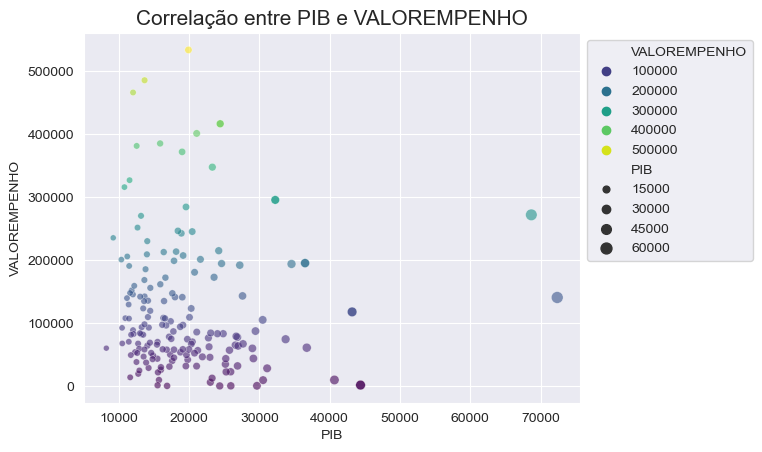

In [220]:
sns.scatterplot(data=base, x='PIB', y='VALOREMPENHO',
                hue='VALOREMPENHO', size='PIB',
                alpha=0.6, palette='viridis')
plt.title('Correlação entre PIB e VALOREMPENHO', fontsize=15)
plt.legend(bbox_to_anchor=(1, 1))
plt.grid(True)
plt.show()

#### Visualizar conjunto de dados usando histogramas

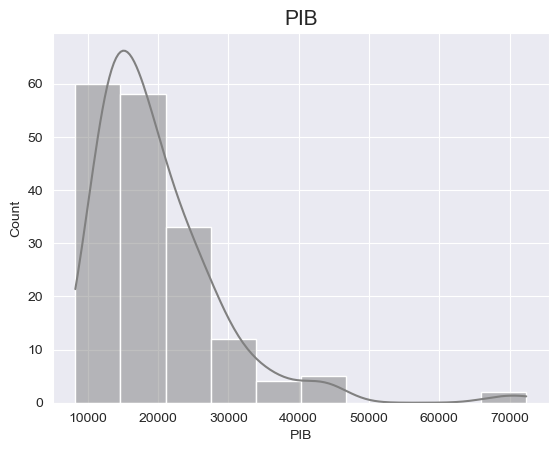

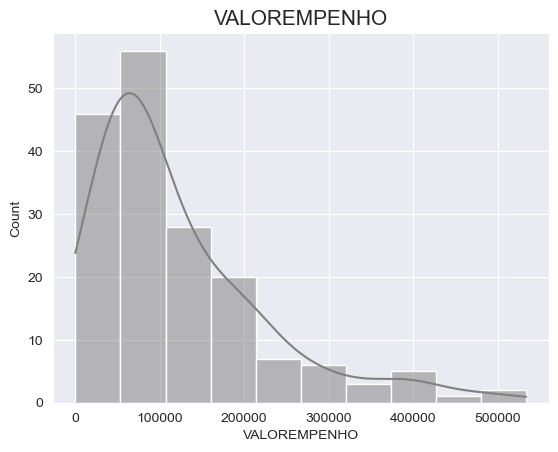

In [221]:
for i, column in enumerate(base.columns[2:], start=1):
    sns.histplot(base[column], kde=True, bins=10, color='grey')
    plt.title(column, fontsize=15)
    plt.show()

#### Exibir municípios com maior PIB e VALOREMPENHO

In [222]:
valor_empenho = base.sort_values(by='VALOREMPENHO').head()
pib = base.sort_values(by='PIB').head()

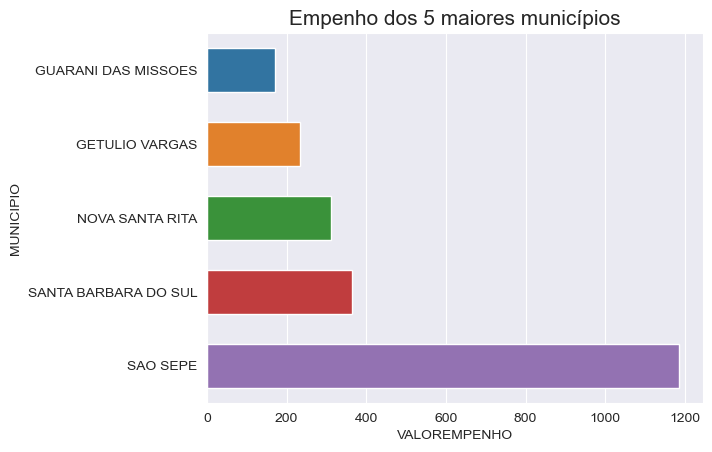

In [223]:
sns.barplot(data=valor_empenho, x='VALOREMPENHO', y='MUNICIPIO', width=0.6)
plt.title("Empenho dos 5 maiores municípios", fontsize=15)
plt.show()

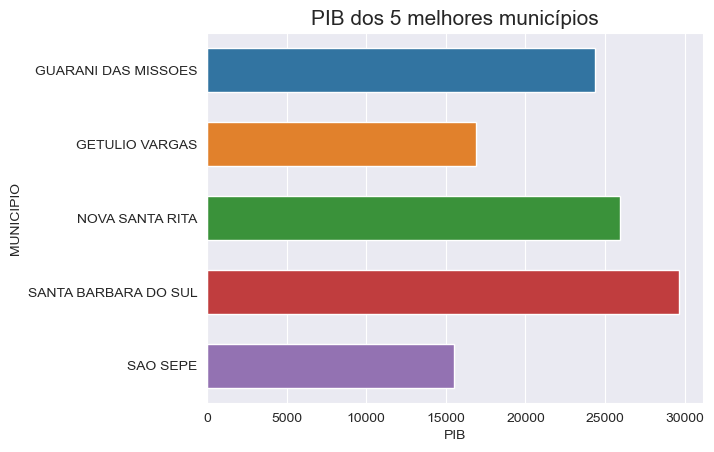

In [224]:
sns.barplot(data=valor_empenho, x='PIB', y='MUNICIPIO', width=0.6)
plt.title("PIB dos 5 melhores municípios", fontsize=15)
plt.show()